# Case Studies 1 and 4
**Sriya A. | 160124733156 | CSE-3 | 2026-2027**

Fundamentals Of Data Science | Assistant Prof. Durga Devi

## Setup
Run top to bottom with both CSV files beside this notebook; Google Colab prompts for any missing file.

In [1]:
from pathlib import Path
from IPython.display import display

def require_csv(filename):
    candidates = [
        Path.cwd() / filename,
        Path.cwd() / '1' / filename,
        Path.cwd() / '4' / filename,
        Path(__file__).resolve().parent / filename if '__file__' in globals() else None,
        Path(__file__).resolve().parent / '1' / filename if '__file__' in globals() else None,
        Path(__file__).resolve().parent / '4' / filename if '__file__' in globals() else None
    ]
    for p in candidates:
        if p and p.exists():
            return p
    try:
        from google.colab import files
        print(f'Upload {filename}')
        uploaded = files.upload()
        if filename in uploaded:
            return Path.cwd() / filename
    except ImportError:
        pass
    raise FileNotFoundError(f'Place {filename!r} beside this notebook or in 1/ or 4/, then rerun this cell.')


## Case Study 1: Online Retail Basket Clustering
Analyze basket composition and compare K-means, hierarchical, DBSCAN and spectral clustering.

### 1.1. Import libraries
Import the analysis libraries, set seed 42, and create a separate folder for retail results.

In [2]:
from pathlib import Path
from collections import Counter
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid', context='notebook')
COLORS = ['#185a7d','#e07a5f','#4d908e','#f2cc8f','#6d597a','#999999']
ASSET_DIR = Path('case_study_1_results'); ASSET_DIR.mkdir(exist_ok=True)

DATA_PATH = require_csv('Online retail_new.csv')
print('Retail environment ready; random seed =', SEED)

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\Admin\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


Retail environment ready; random seed = 42


### 1.2. Load and clean baskets
Read the headerless CSV, clean product names, and keep repeated transactions as valid evidence.

In [3]:
raw = pd.read_csv(DATA_PATH, header=None)
print('Raw shape:', raw.shape)  # The first row is a transaction, not a header.
display(raw.head())

def clean_basket(row):
    items = []
    for value in row.dropna().astype(str):
        item = ' '.join(value.strip().lower().split())
        if item and item not in items:
            items.append(item)
    return items

baskets = [clean_basket(row) for _, row in raw.iterrows()]
basket_sizes = np.array([len(b) for b in baskets])
item_counts = Counter(item for basket in baskets for item in set(basket))
print('Transactions:', len(baskets))
print('Unique products:', len(item_counts))
print('Empty baskets:', int((basket_sizes == 0).sum()))
print('Exact duplicate rows beyond first occurrence:', pd.Series([tuple(sorted(b)) for b in baskets]).duplicated().sum())
assert len(baskets) == len(raw) and (basket_sizes > 0).all()

Raw shape: (7501, 20)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Transactions: 7501
Unique products: 119
Empty baskets: 0
Exact duplicate rows beyond first occurrence: 2347


### 1.3. Check the companion workbook
Compare the cleaned CSV with the optional Excel workbook when it is available.

In [4]:
# Optional cross-file validation when the companion workbook is available.
xlsx_path = DATA_PATH.with_name('Online retail.xlsx')
if xlsx_path.exists():
    workbook = pd.read_excel(xlsx_path, header=None).dropna(how='all')
    excel_baskets = [clean_basket(pd.Series(str(row.iloc[0]).split(','))) for _, row in workbook.iterrows()]
    print('Workbook baskets:', len(excel_baskets), '| Identical to CSV:', excel_baskets == baskets)
else:
    print('Companion workbook not supplied; CSV validation completed independently.')

Companion workbook not supplied; CSV validation completed independently.


### 1.4. Summarize transactions
Calculate basket sizes, product frequencies and the share of item occurrences represented by the top ten products.

In [5]:
size_stats = pd.Series(basket_sizes).describe(percentiles=[.25,.5,.75,.9,.95]).round(3)
frequency = pd.Series(item_counts).sort_values(ascending=False)
summary = {
    'transactions': len(baskets),
    'products': len(item_counts),
    'total_item_occurrences': int(basket_sizes.sum()),
    'mean_size': float(basket_sizes.mean()),
    'median_size': float(np.median(basket_sizes)),
    'max_size': int(basket_sizes.max()),
    'singleton_share': float((basket_sizes == 1).mean()),
    'small_share_le_2': float((basket_sizes <= 2).mean()),
    'large_share_ge_10': float((basket_sizes >= 10).mean()),
    'top10_occurrence_share': float(frequency.head(10).sum()/frequency.sum())
}
display(size_stats.to_frame('basket size'))
display(frequency.head(15).rename('basket frequency').to_frame())
print(json.dumps(summary, indent=2))

,basket size
count,7501.000
mean,3.914
std,2.905
min,1.000
25%,2.000
50%,3.000
75%,5.000
90%,8.000
95%,10.000
max,20.000


,basket frequency
mineral water,1788
eggs,1348
spaghetti,1306
french fries,1282
chocolate,1229
green tea,991
milk,972
ground beef,737
frozen vegetables,715
pancakes,713


{
  "transactions": 7501,
  "products": 119,
  "total_item_occurrences": 29358,
  "mean_size": 3.913878149580056,
  "median_size": 3.0,
  "max_size": 20,
  "singleton_share": 0.2338354886015198,
  "small_share_le_2": 0.41487801626449805,
  "large_share_ge_10": 0.05265964538061592,
  "top10_occurrence_share": 0.3774439675727229
}


### 1.5. Plot popular products
Show the twenty most common products by the number of baskets containing each item.

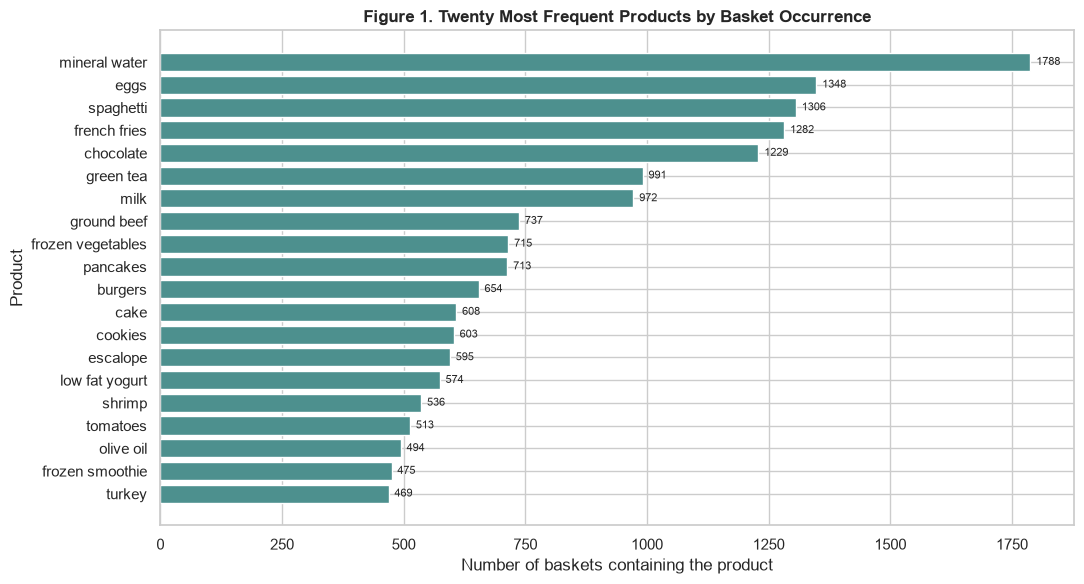

Interpretation: Frequent products dominate basket composition, but frequency alone does not establish profitability.


In [6]:
fig, ax = plt.subplots(figsize=(11,6))
top = frequency.head(20).sort_values()
ax.barh(top.index, top.values, color=COLORS[2])
ax.set_title('Figure 1. Twenty Most Frequent Products by Basket Occurrence', weight='bold')
ax.set_xlabel('Number of baskets containing the product')
ax.set_ylabel('Product')
for i,v in enumerate(top.values): ax.text(v+12,i,str(v),va='center',fontsize=8)
fig.tight_layout(); fig.savefig(ASSET_DIR/'fig1_product_frequency.png',dpi=180); plt.show()

print('Interpretation: Frequent products dominate basket composition, but frequency alone does not establish profitability.')

### 1.6. Plot basket sizes
Compare the mean, median and distribution of distinct products per transaction.

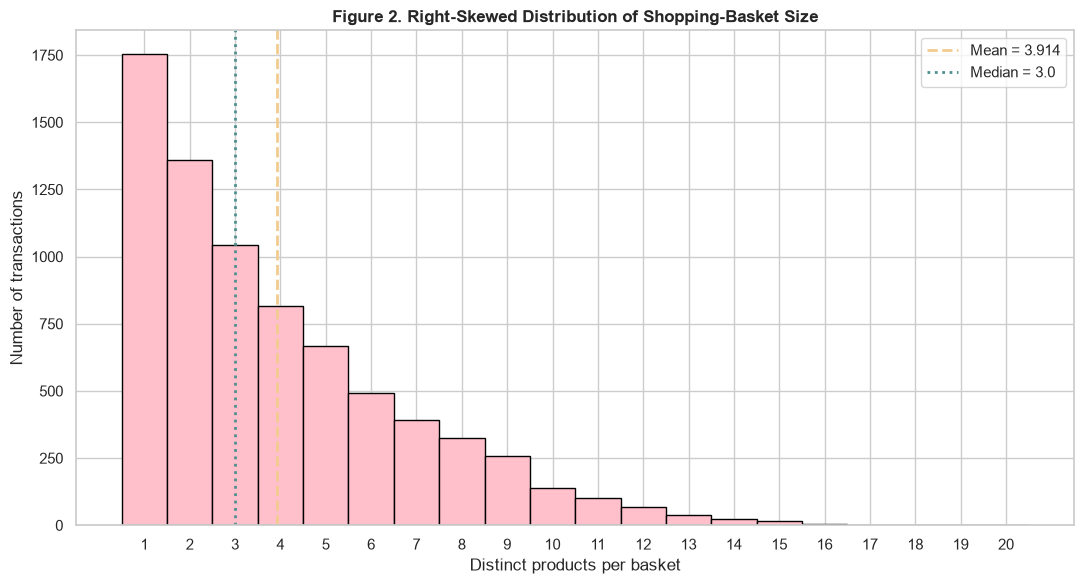

Interpretation: Mean basket size is 3.91 versus median 3; 23.4% of baskets contain one item.


In [7]:
fig, ax = plt.subplots(figsize=(11,6))
bins = np.arange(1, basket_sizes.max()+2)-0.5
ax.hist(basket_sizes,bins=bins,color="pink",edgecolor='black')
ax.axvline(basket_sizes.mean(),color=COLORS[3],ls='--',lw=2,label=f'Mean = {basket_sizes.mean():.3f}')
ax.axvline(np.median(basket_sizes),color=COLORS[2],ls=':',lw=2,label=f'Median = {np.median(basket_sizes):.1f}')
ax.set_title('Figure 2. Right-Skewed Distribution of Shopping-Basket Size',weight='bold')
ax.set_xlabel('Distinct products per basket'); ax.set_ylabel('Number of transactions')
ax.set_xticks(range(1, int(basket_sizes.max()) + 1)); ax.legend(); fig.tight_layout()
fig.savefig(ASSET_DIR/'fig2_basket_size.png',dpi=180); plt.show()
print(f'Interpretation: Mean basket size is {basket_sizes.mean():.2f} versus median {np.median(basket_sizes):.0f}; {(basket_sizes == 1).mean():.1%} of baskets contain one item.')

### 1.7. Encode products and apply PCA
Convert baskets to binary product indicators and retain 20 principal components for clustering.

In [8]:
encoder = MultiLabelBinarizer()
X = encoder.fit_transform(baskets).astype(np.float32)
products = np.array(encoder.classes_)
print('One-hot matrix:', X.shape, '| Density:', round(X.mean(),4))
pca = PCA(n_components=20, random_state=SEED)
Z = pca.fit_transform(X)
Z_standardized = StandardScaler().fit_transform(Z)  # used by DBSCAN to balance PC distance scales
explained = pca.explained_variance_ratio_
print('Variance retained by 20 PCs:', round(explained.sum(),4))
print('Variance retained by first 2 PCs:', round(explained[:2].sum(),4))

One-hot matrix: (7501, 119) | Density: 0.0329
Variance retained by 20 PCs: 0.549
Variance retained by first 2 PCs: 0.1118


### 1.8. Check retained variance
Plot cumulative PCA variance to show how much information the reduced representation preserves.

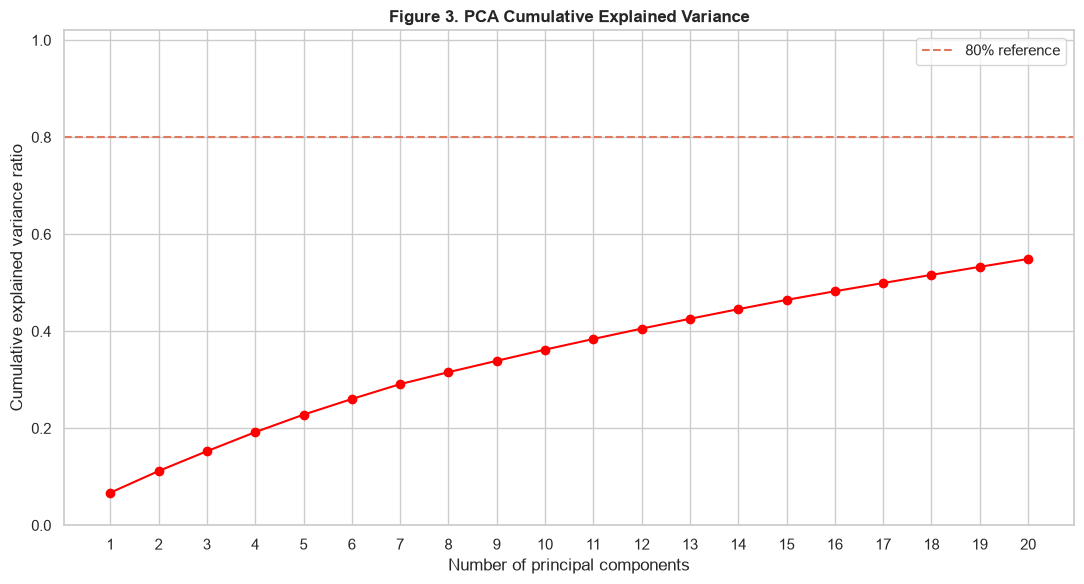

Interpretation: Twenty PCs retain 54.9% of variance; the first two retain only 11.2%.


In [9]:
fig, ax = plt.subplots(figsize=(11,6))
ax.plot(range(1,21),np.cumsum(explained),marker='o',color="red")
ax.axhline(.8,color=COLORS[1],ls='--',label='80% reference')
ax.set_title('Figure 3. PCA Cumulative Explained Variance',weight='bold')
ax.set_xlabel('Number of principal components'); ax.set_ylabel('Cumulative explained variance ratio')
ax.set_xticks(range(1,21)); ax.set_ylim(0,1.02); ax.legend(); fig.tight_layout()
fig.savefig(ASSET_DIR/'fig3_pca_variance.png',dpi=180); plt.show()
print(f'Interpretation: Twenty PCs retain {explained.sum():.1%} of variance; the first two retain only {explained[:2].sum():.1%}.')

### 1.9. Compare cluster counts
Compare silhouette and Davies-Bouldin scores for K = 2-8; use K = 5 as a descriptive compromise, not a proven optimum.

C:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", l

,silhouette,davies_bouldin
k,,
2,0.1782,2.4995
3,0.1621,2.3552
4,0.1545,2.1904
5,0.1581,2.1169
6,0.1511,2.0350
7,0.1385,1.9978
8,0.1418,2.0979


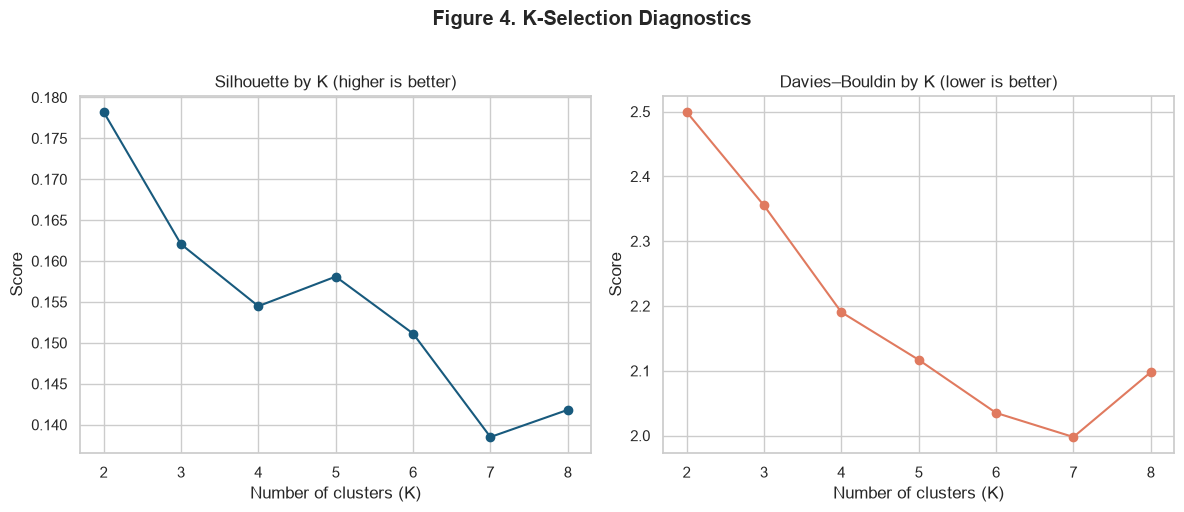

In [10]:
k_rows=[]
for k in range(2,9):
    labels = KMeans(n_clusters=k,n_init=20,random_state=SEED).fit_predict(Z)
    k_rows.append({'k':k,
                   'silhouette':silhouette_score(Z,labels,sample_size=3000,random_state=SEED),
                   'davies_bouldin':davies_bouldin_score(Z,labels)})
k_scan = pd.DataFrame(k_rows).set_index('k')
display(k_scan.round(4))
fig, axes = plt.subplots(1,2,figsize=(12,5))
axes[0].plot(k_scan.index,k_scan.silhouette,marker='o',color=COLORS[0]); axes[0].set_title('Silhouette by K (higher is better)')
axes[1].plot(k_scan.index,k_scan.davies_bouldin,marker='o',color=COLORS[1]); axes[1].set_title('Davies–Bouldin by K (lower is better)')
for ax in axes: ax.set_xlabel('Number of clusters (K)'); ax.set_ylabel('Score'); ax.set_xticks(k_scan.index)
fig.suptitle('Figure 4. K-Selection Diagnostics',weight='bold',y=1.02)
fig.tight_layout(); fig.savefig(ASSET_DIR/'fig4_k_selection.png',dpi=180,bbox_inches='tight'); plt.show()

### 1.10. Fit four clustering methods
Fit K-means, Ward and DBSCAN on all baskets, and spectral clustering on a fixed 2,000-basket sample.

In [11]:
eval_idx = rng.choice(len(Z),size=2000,replace=False)
Z_eval = Z[eval_idx]
labels_kmeans = KMeans(n_clusters=5,n_init=20,random_state=SEED).fit_predict(Z)
labels_hier = AgglomerativeClustering(n_clusters=5,linkage='ward').fit_predict(Z)
labels_dbscan = DBSCAN(eps=3.5,min_samples=15,n_jobs=-1).fit_predict(Z_standardized)
spectral = SpectralClustering(n_clusters=5,affinity='nearest_neighbors',n_neighbors=20,
                              assign_labels='kmeans',n_init=10,random_state=SEED)
labels_spectral_eval = spectral.fit_predict(Z_eval)
print('Full-sample K-means sizes:',np.bincount(labels_kmeans))
print('Full-sample hierarchical sizes:',np.bincount(labels_hier))
print('DBSCAN clusters/noise:',len(set(labels_dbscan)-{-1}),int((labels_dbscan==-1).sum()))
print('Evaluation-sample spectral sizes:',np.bincount(labels_spectral_eval))

Full-sample K-means sizes: [1193  908  900 1161 3339]
Full-sample hierarchical sizes: [2095 1680  913 2358  455]
DBSCAN clusters/noise: 2 1313
Evaluation-sample spectral sizes: [ 243 1609   78   20   50]


### 1.11. Evaluate clustering
Compare internal scores and coverage while accounting for DBSCAN noise, different distance spaces and the spectral sample fit.

In [12]:
def partition_metrics(space, labels, coverage=1.0, note=''):
    if not 2 <= len(np.unique(labels)) < len(labels):
        return {'silhouette': np.nan, 'davies_bouldin': np.nan,
                'coverage': coverage, 'note': note + '; fewer than two valid clusters'}
    return {'silhouette':silhouette_score(space,labels),
            'davies_bouldin':davies_bouldin_score(space,labels),
            'coverage':coverage,'note':note}

metric_rows={}
metric_rows['K-means']=partition_metrics(Z_eval,labels_kmeans[eval_idx],1.0,'Full-data fit; 5 clusters')
metric_rows['Ward hierarchical']=partition_metrics(Z_eval,labels_hier[eval_idx],1.0,'Full-data fit; 5 clusters')
nonnoise_eval = labels_dbscan[eval_idx] >= 0
metric_rows['DBSCAN (non-noise)']=partition_metrics(Z_standardized[eval_idx][nonnoise_eval],labels_dbscan[eval_idx][nonnoise_eval],float(nonnoise_eval.mean()),'Noise excluded; standardized PC space')
metric_rows['Spectral (sample fit)']=partition_metrics(Z_eval,labels_spectral_eval,1.0,'Fit only on evaluation sample')
metrics=pd.DataFrame(metric_rows).T
metrics.insert(0,'model',metrics.index)
metrics=metrics.reset_index(drop=True)
display(metrics.round(4))
print('Interpretation: Different distance spaces and noise coverage limit score comparability; these are internal diagnostics, not out-of-sample validation.')

,model,silhouette,davies_bouldin,coverage,note
0,K-means,0.157155,2.089409,1.0,Full-data fit; 5 clusters
1,Ward hierarchical,0.036833,3.526003,1.0,Full-data fit; 5 clusters
2,DBSCAN (non-noise),0.23041,1.106293,0.8285,Noise excluded; standardized PC space
3,Spectral (sample fit),-0.14355,1.993141,1.0,Fit only on evaluation sample


Interpretation: Different distance spaces and noise coverage limit score comparability; these are internal diagnostics, not out-of-sample validation.


### 1.12. Plot the hierarchy
Use a 250-basket sample to visualize Ward merge distances without replacing the full-data clustering.

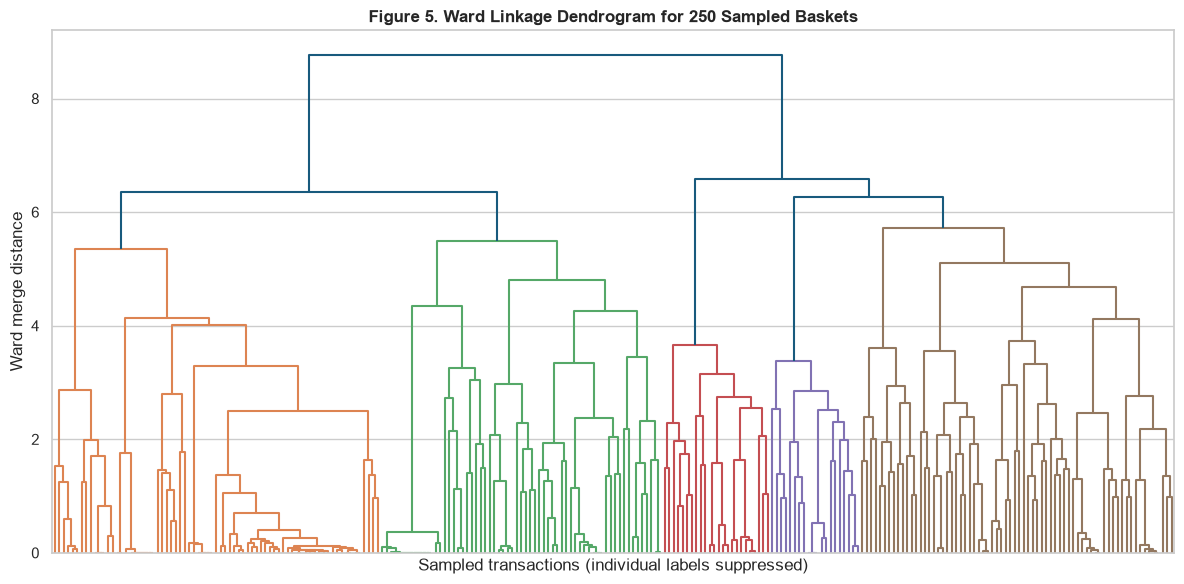

Interpretation: Higher merges join more dissimilar baskets; this sampled tree is only a visual diagnostic.


In [13]:
dendro_idx = rng.choice(len(Z),size=250,replace=False)
link = linkage(Z[dendro_idx],method='ward')
fig,ax=plt.subplots(figsize=(12,6))
dendrogram(link,no_labels=True,color_threshold=None,above_threshold_color=COLORS[0],ax=ax)
ax.set_title('Figure 5. Ward Linkage Dendrogram for 250 Sampled Baskets',weight='bold')
ax.set_xlabel('Sampled transactions (individual labels suppressed)'); ax.set_ylabel('Ward merge distance')
fig.tight_layout(); fig.savefig(ASSET_DIR/'fig5_dendrogram.png',dpi=180); plt.show()
print('Interpretation: Higher merges join more dissimilar baskets; this sampled tree is only a visual diagnostic.')

### 1.13. Visualize K-means groups
Display K-means assignments on two PCA axes, which show only part of the fitted 20-dimensional structure.

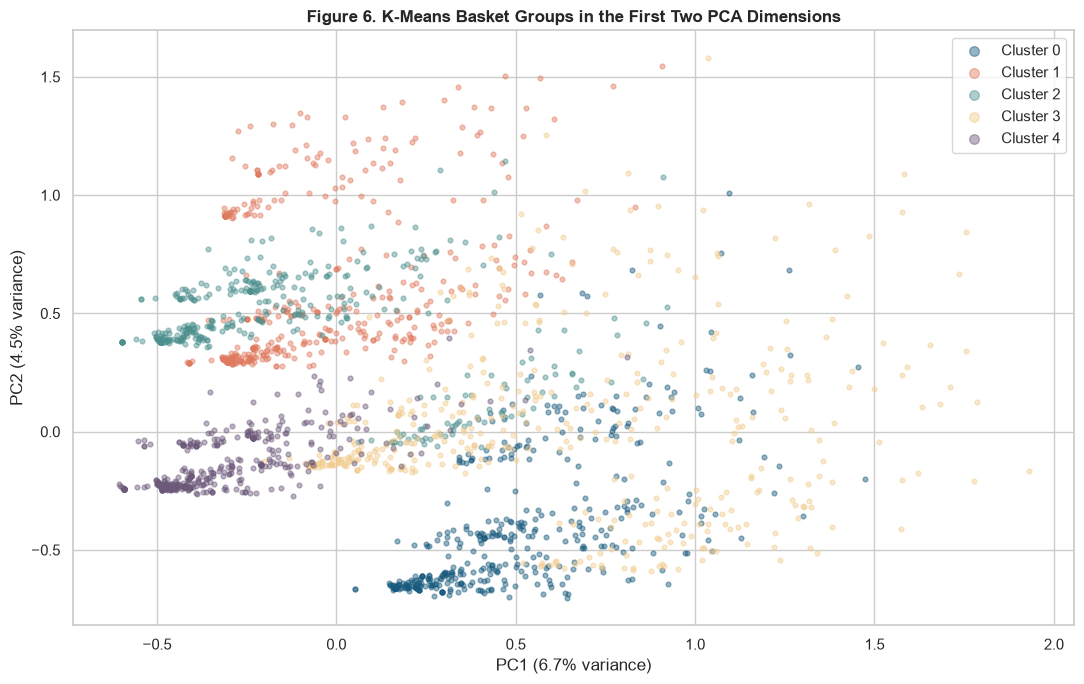

Interpretation: Overlap in two PCs cannot establish cluster quality in the full 20-dimensional representation.


In [14]:
fig,ax=plt.subplots(figsize=(11,7))
for c in range(5):
    idx=rng.choice(np.where(labels_kmeans==c)[0],size=min(450,(labels_kmeans==c).sum()),replace=False)
    ax.scatter(Z[idx,0],Z[idx,1],s=12,alpha=.45,color=COLORS[c],label=f'Cluster {c}')
ax.set_title('Figure 6. K-Means Basket Groups in the First Two PCA Dimensions',weight='bold')
ax.set_xlabel(f'PC1 ({explained[0]:.1%} variance)'); ax.set_ylabel(f'PC2 ({explained[1]:.1%} variance)')
ax.legend(markerscale=2); fig.tight_layout(); fig.savefig(ASSET_DIR/'fig6_pca_clusters.png',dpi=180); plt.show()
print('Interpretation: Overlap in two PCs cannot establish cluster quality in the full 20-dimensional representation.')

### 1.14. Describe cluster profiles
Compare product prevalence, lift and average basket size to interpret the five groups.


Cluster 0: n=1193, mean basket size=4.96
mineral water (100%, lift 4.20), eggs (22%, lift 1.23), chocolate (20%, lift 1.25), milk (19%, lift 1.43), ground beef (14%, lift 1.46), frozen vegetables (13%, lift 1.41)

Cluster 1: n=908, mean basket size=4.21
eggs (100%, lift 5.56), french fries (25%, lift 1.44), burgers (16%, lift 1.84), green tea (15%, lift 1.12), chocolate (13%, lift 0.81), milk (12%, lift 0.93)

Cluster 2: n=900, mean basket size=4.24
french fries (100%, lift 5.85), chocolate (18%, lift 1.11), green tea (16%, lift 1.22), mineral water (15%, lift 0.63), escalope (11%, lift 1.36), pancakes (10%, lift 1.02)

Cluster 3: n=1161, mean basket size=6.45
spaghetti (100%, lift 5.73), mineral water (39%, lift 1.62), ground beef (25%, lift 2.59), chocolate (23%, lift 1.41), milk (22%, lift 1.71), frozen vegetables (18%, lift 1.84)

Cluster 4: n=3339, mean basket size=2.49
chocolate (13%, lift 0.79), green tea (12%, lift 0.93), cookies (12%, lift 1.46), milk (9%, lift 0.69), escalop

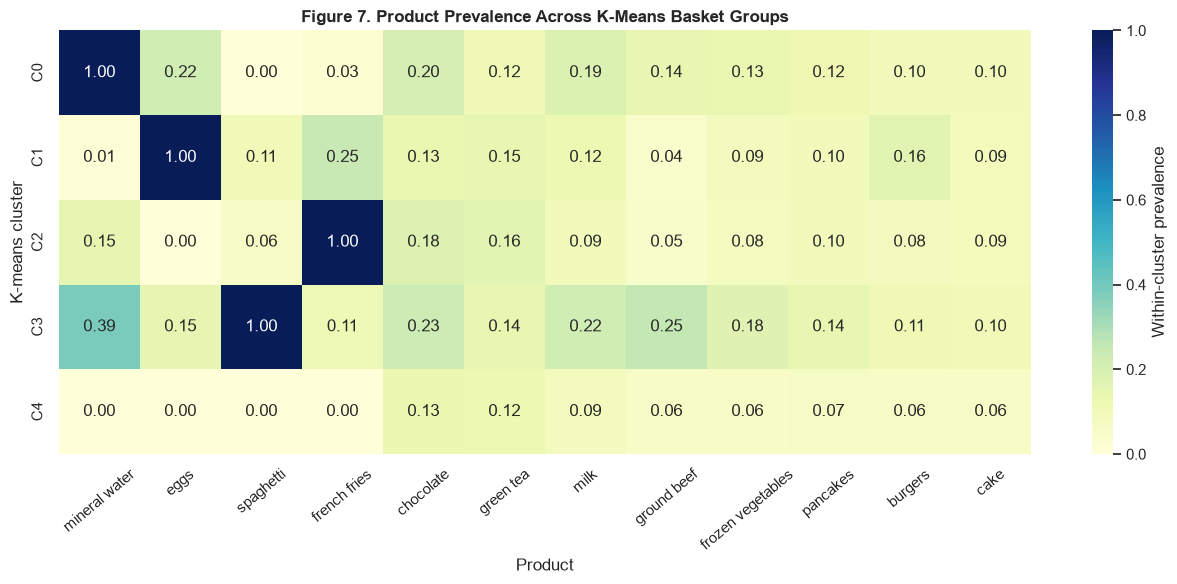

Interpretation: Product prevalence and lift describe basket groups, not proven customer types or causal cross-selling effects.


In [15]:
profile_rows=[]
overall_prev=X.mean(axis=0)
for c in range(5):
    mask=labels_kmeans==c
    prev=X[mask].mean(axis=0)
    lift=prev/(overall_prev+1e-12)
    for rank,idx in enumerate(np.argsort(-prev)[:6],1):
        profile_rows.append({'cluster':c,'baskets':int(mask.sum()),
                             'mean_size':float(basket_sizes[mask].mean()),
                             'rank':rank,'product':products[idx],
                             'prevalence':float(prev[idx]),'lift':float(lift[idx])})
profiles=pd.DataFrame(profile_rows)
for c in range(5):
    p=profiles[profiles.cluster==c]
    print()
    print(f"Cluster {c}: n={p.baskets.iloc[0]}, mean basket size={p.mean_size.iloc[0]:.2f}")
    print(', '.join(f"{r.product} ({r.prevalence:.0%}, lift {r.lift:.2f})" for r in p.itertuples()))

top_products=list(frequency.head(12).index)
heat=np.array([[X[labels_kmeans==c][:,list(products).index(p)].mean() for p in top_products] for c in range(5)])
fig,ax=plt.subplots(figsize=(13,6))
sns.heatmap(heat,annot=True,fmt='.2f',cmap='YlGnBu',xticklabels=top_products,
            yticklabels=[f'C{c}' for c in range(5)],cbar_kws={'label':'Within-cluster prevalence'},ax=ax)
ax.set_title('Figure 7. Product Prevalence Across K-Means Basket Groups',weight='bold')
ax.set_xlabel('Product'); ax.set_ylabel('K-means cluster'); ax.tick_params(axis='x',rotation=40)
fig.tight_layout(); fig.savefig(ASSET_DIR/'fig7_cluster_heatmap.png',dpi=180); plt.show()
print('Interpretation: Product prevalence and lift describe basket groups, not proven customer types or causal cross-selling effects.')

### 1.15. Save retail results
Export descriptive statistics, PCA variance, clustering scores and profiles to JSON.

In [16]:
results = {'summary':summary,
           'pca_variance_20':float(explained.sum()),
           'pca_variance_2':float(explained[:2].sum()),
           'k_scan':k_scan.reset_index().to_dict('records'),
           'metrics':metrics.to_dict('records'),
           'dbscan_noise_share':float((labels_dbscan==-1).mean()),
           'kmeans_sizes':np.bincount(labels_kmeans).tolist(),
           'profiles':profiles.to_dict('records')}
with open(ASSET_DIR/'results.json','w') as f: json.dump(results,f,indent=2)
print('Saved results audit trail. Analysis complete.')

Saved results audit trail. Analysis complete.


**Note:** Reading the retail CSV with header=None restores its first transaction, so corrected results can differ from the original notebook.

## Case Study 4: Predicting Student Dropout and Academic Success
Compare final student outcomes and evaluate multiclass logistic regression using information available by semester one.

### 4.1. Import libraries
Load dependencies, reset plot styling, and create a separate folder for student results.

In [17]:
from pathlib import Path
import hashlib, json, platform, warnings
from itertools import combinations
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('error', category=ConvergenceWarning)
ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
RESULTS = ROOT / 'case_study_4_results'
RESULTS.mkdir(exist_ok=True)
DATA = require_csv('Studentdata.csv')
SEED = 42
CLASSES = ['Dropout', 'Enrolled', 'Graduate']
COLORS = ['#C55A45', '#D7A535', '#218A87']
plt.style.use('default')
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':180, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.titleweight':'bold'})
versions = dict(python=platform.python_version(), numpy=np.__version__,
                pandas=pd.__version__, scipy=scipy.__version__,
                sklearn=sklearn.__version__, matplotlib=matplotlib.__version__)
print('Execution versions:', versions)
print('Dataset SHA-256:', hashlib.sha256(DATA.read_bytes()).hexdigest())
def table(frame):
    print(frame.to_string(float_format=lambda x:f'{x:.4f}'))
def finish(name):
    """Save and display the chart, then close the figure."""
    plt.tight_layout()
    plt.savefig(RESULTS / f'{name}.png', bbox_inches='tight', facecolor='white')
    if 'inline' in matplotlib.get_backend():
        plt.show()
    plt.close()

Execution versions: {'python': '3.12.10', 'numpy': '2.5.1', 'pandas': '2.3.3', 'scipy': '1.18.0', 'sklearn': '1.9.0', 'matplotlib': '3.11.1'}
Dataset SHA-256: 3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae


### 4.2. Read and classify variables
Load the student CSV and distinguish numerical values, categorical codes, binary indicators and the target.

In [18]:
df = pd.read_csv(DATA, sep=';')
df.columns = df.columns.str.strip()
print('Rows and columns:', df.shape)
print('\nFirst five records:')
table(df.head())
print('\nStorage types:')
print(df.dtypes.to_string())
nominal = ['Marital status','Application mode','Course','Previous qualification',
           'Nacionality',"Mother's qualification","Father's qualification",
           "Mother's occupation","Father's occupation"]
binary = ['Daytime/evening attendance','Displaced','Educational special needs',
          'Debtor','Tuition fees up to date','Gender','Scholarship holder','International']
numeric = [c for c in df if c not in nominal+binary+['Target']]
schema = pd.DataFrame({'attribute':df.columns,
    'semantic_type':['Target: nominal' if c=='Target' else 'Nominal code' if c in nominal
                     else 'Binary code' if c in binary else 'Ordinal (scaled numeric)'
                     if c=='Application order' else 'Numerical' for c in df],
    'dtype':[str(df[c].dtype) for c in df],
    'unique_values':[df[c].nunique() for c in df]})
table(schema)
schema.to_csv(RESULTS/'data_dictionary.csv',index=False)

Rows and columns: (4424, 37)

First five records:
   Marital status  Application mode  Application order  Course  Daytime/evening attendance  Previous qualification  Previous qualification (grade)  Nacionality  Mother's qualification  Father's qualification  Mother's occupation  Father's occupation  Admission grade  Displaced  Educational special needs  Debtor  Tuition fees up to date  Gender  Scholarship holder  Age at enrollment  International  Curricular units 1st sem (credited)  Curricular units 1st sem (enrolled)  Curricular units 1st sem (evaluations)  Curricular units 1st sem (approved)  Curricular units 1st sem (grade)  Curricular units 1st sem (without evaluations)  Curricular units 2nd sem (credited)  Curricular units 2nd sem (enrolled)  Curricular units 2nd sem (evaluations)  Curricular units 2nd sem (approved)  Curricular units 2nd sem (grade)  Curricular units 2nd sem (without evaluations)  Unemployment rate  Inflation rate     GDP    Target
0               1              

### 4.3. Check data quality
Audit missingness, duplicates and ranges while retaining legitimate zero grades and older students.

In [19]:
grade1 = 'Curricular units 1st sem (grade)'
approved1 = 'Curricular units 1st sem (approved)'
count_cols = [c for c in numeric if c.startswith('Curricular') and '(grade)' not in c]
audit = dict(rows=len(df), columns=len(df.columns), predictors=len(df.columns)-1,
    missing_cells=int(df.isna().sum().sum()),
    blank_string_cells=int(df.select_dtypes('object').apply(lambda s:s.str.strip().eq('').sum()).sum()),
    duplicate_rows=int(df.duplicated().sum()),
    duplicate_predictor_rows=int(df.drop(columns='Target').duplicated().sum()),
    nonfinite_cells=int((~np.isfinite(df.select_dtypes('number'))).sum().sum()),
    invalid_binary_cells=int(sum((~df[c].isin([0,1])).sum() for c in binary)),
    invalid_count_cells=int(sum(((df[c]<0)|(df[c]%1!=0)).sum() for c in count_cols)),
    admission_outside_0_200=int((~df['Admission grade'].between(0,200)).sum()),
    previous_grade_outside_0_200=int((~df['Previous qualification (grade)'].between(0,200)).sum()),
    semester_grade_outside_0_20=int(sum((~df[c].between(0,20)).sum() for c in [grade1,'Curricular units 2nd sem (grade)'])),
    application_order_outside_0_9=int((~df['Application order'].between(0,9)).sum()),
    age_outside_15_100=int((~df['Age at enrollment'].between(15,100)).sum()),
    first_semester_zero_grade=int(df[grade1].eq(0).sum()),
    zero_grade_positive_approvals=int((df[grade1].eq(0)&df[approved1].gt(0)).sum()),
    positive_grade_zero_approvals=int((df[grade1].gt(0)&df[approved1].eq(0)).sum()))
print(json.dumps(audit,indent=2))
assert set(df.Target.unique()) == set(CLASSES)
assert audit['missing_cells'] == audit['duplicate_rows'] == 0
print('Age range:',df['Age at enrollment'].min(),'-',df['Age at enrollment'].max())
print('No missing cells or duplicate rows: no record removal is applied.')
print('Zero grades are retained. Range checks cannot prove each original record is correct.')

{
  "rows": 4424,
  "columns": 37,
  "predictors": 36,
  "missing_cells": 0,
  "blank_string_cells": 0,
  "duplicate_rows": 0,
  "duplicate_predictor_rows": 0,
  "nonfinite_cells": 0,
  "invalid_binary_cells": 0,
  "invalid_count_cells": 0,
  "admission_outside_0_200": 0,
  "previous_grade_outside_0_200": 0,
  "semester_grade_outside_0_20": 0,
  "application_order_outside_0_9": 0,
  "age_outside_15_100": 0,
  "first_semester_zero_grade": 718,
  "zero_grade_positive_approvals": 0,
  "positive_grade_zero_approvals": 0
}
Age range: 17 - 70
No missing cells or duplicate rows: no record removal is applied.
Zero grades are retained. Range checks cannot prove each original record is correct.


### 4.4. Plot outcome distribution
Count Dropout, Enrolled and Graduate students to assess class imbalance.

          count  percent
Target                  
Dropout    1421  32.1203
Enrolled    794  17.9476
Graduate   2209  49.9322


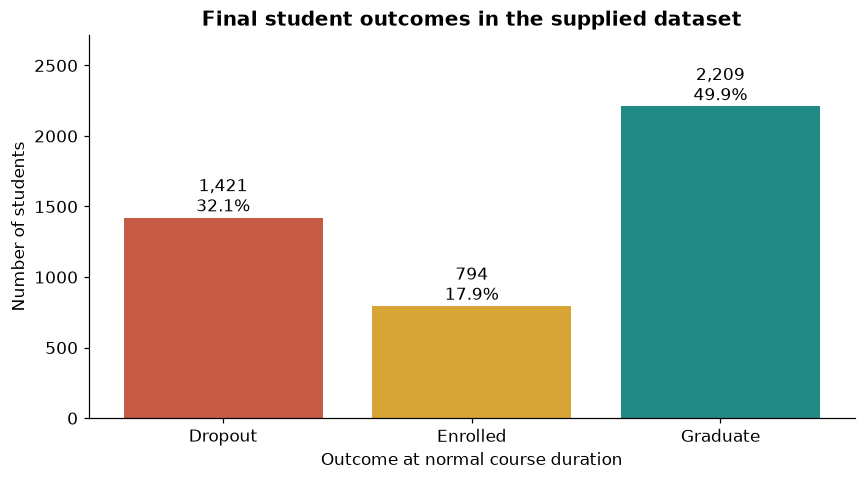

Graduate is the largest class (49.9%); Enrolled is the smallest (17.9%).
A majority-class classifier can appear accurate while missing all Dropout and Enrolled cases. Macro metrics give each class equal weight.


In [20]:
counts = df.Target.value_counts().reindex(CLASSES)
distribution = pd.DataFrame({'count':counts,'percent':counts/len(df)*100})
table(distribution)
fig,ax = plt.subplots(figsize=(8,4.5))
bars = ax.bar(CLASSES,counts,color=COLORS)
ax.set(title='Final student outcomes in the supplied dataset',
       xlabel='Outcome at normal course duration',ylabel='Number of students',ylim=(0,counts.max()*1.23))
for b,n in zip(bars,counts):
    ax.text(b.get_x()+b.get_width()/2,n+45,f'{n:,}\n{n/len(df):.1%}',ha='center')
finish('01_outcomes')
print(f'Graduate is the largest class ({counts.Graduate/len(df):.1%}); Enrolled is the smallest ({counts.Enrolled/len(df):.1%}).')
print('A majority-class classifier can appear accurate while missing all Dropout and Enrolled cases. Macro metrics give each class equal weight.')

### 4.5. Summarize numerical attributes
Calculate descriptive statistics and plot age and admission-grade distributions.

                                        count     mean     std     min      25%      50%      75%      max
Age at enrollment                   4424.0000  23.2651  7.5878 17.0000  19.0000  20.0000  25.0000  70.0000
Admission grade                     4424.0000 126.9781 14.4820 95.0000 117.9000 126.1000 134.8000 190.0000
Previous qualification (grade)      4424.0000 132.6133 13.1883 95.0000 125.0000 133.1000 140.0000 190.0000
Curricular units 1st sem (grade)    4424.0000  10.6408  4.8437  0.0000  11.0000  12.2857  13.4000  18.8750
Curricular units 1st sem (approved) 4424.0000   4.7066  3.0942  0.0000   3.0000   5.0000   6.0000  26.0000


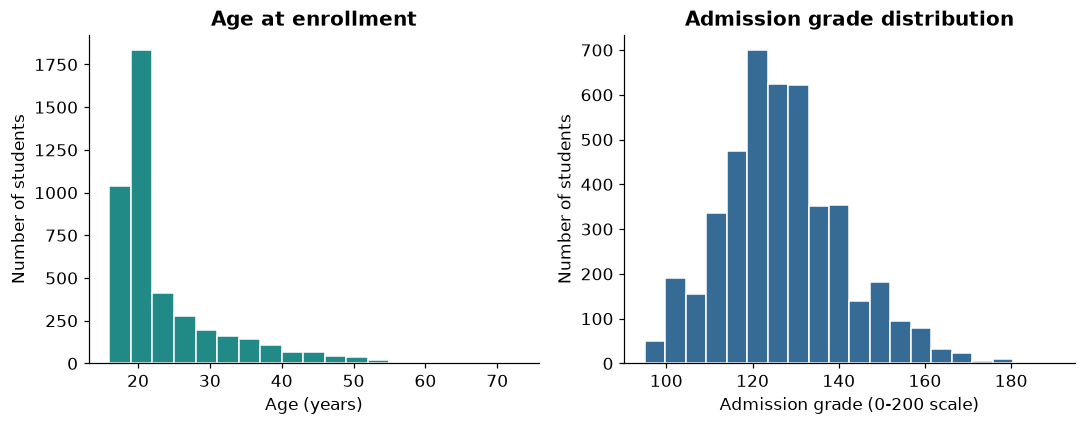

Age median 20, mean 23.27, skewness 2.05: the older tail is not automatically erroneous.
Admission-grade mean 126.98, SD 14.48, range 95.0-190.0.


In [21]:
selected = ['Age at enrollment','Admission grade','Previous qualification (grade)',grade1,approved1]
descriptive = df[selected].describe().T
table(descriptive)
descriptive.to_csv(RESULTS/'descriptive_statistics.csv')
fig,axes = plt.subplots(1,2,figsize=(10,4))
axes[0].hist(df['Age at enrollment'],bins=np.arange(16,74,3),color='#218A87',edgecolor='white')
axes[0].set(title='Age at enrollment',xlabel='Age (years)',ylabel='Number of students')
axes[1].hist(df['Admission grade'],bins=20,color='#366B96',edgecolor='white')
axes[1].set(title='Admission grade distribution',xlabel='Admission grade (0-200 scale)',ylabel='Number of students')
finish('02_histograms')
print(f"Age median {df['Age at enrollment'].median():.0f}, mean {df['Age at enrollment'].mean():.2f}, skewness {df['Age at enrollment'].skew():.2f}: the older tail is not automatically erroneous.")
print(f"Admission-grade mean {df['Admission grade'].mean():.2f}, SD {df['Admission grade'].std():.2f}, range {df['Admission grade'].min():.1f}-{df['Admission grade'].max():.1f}.")

### 4.6. Compare admission grades
Compare admission-grade summaries and box plots across final outcomes.

         Age at enrollment                Admission grade                  Previous qualification (grade)                  Curricular units 1st sem (grade)                Curricular units 1st sem (approved)              
                      mean  median    std            mean   median     std                           mean   median     std                             mean  median    std                                mean median    std
Target                                                                                                                                                                                                                      
Dropout            26.0690 23.0000 8.7040        124.9614 123.6000 15.1252                       131.1141 133.1000 12.8734                           7.2567 10.9286 6.0311                              2.5517 2.0000 2.8576
Enrolled           22.3690 20.0000 6.3027        125.5343 124.1000 13.7926                       131.2084 130.0000 1

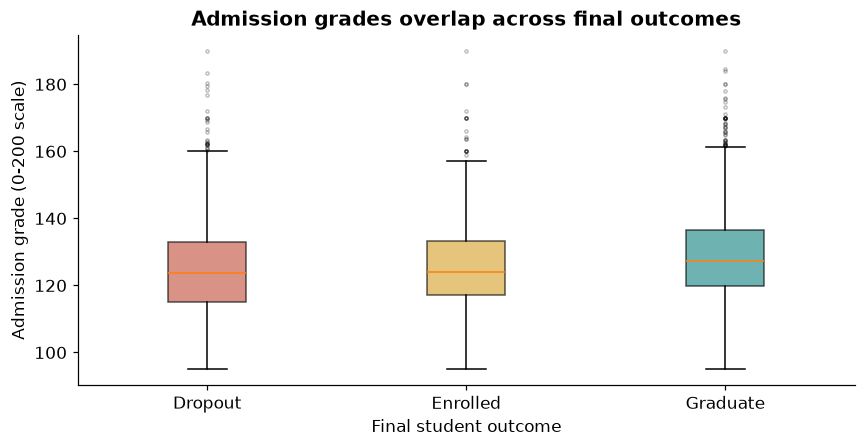

Admission-grade medians: {'Dropout': 123.6, 'Enrolled': 124.1, 'Graduate': 127.4}
The distributions overlap substantially; admission grade alone does not separate the three outcomes.


In [22]:
by_outcome = df.groupby('Target')[selected].agg(['mean','median','std']).reindex(CLASSES)
table(by_outcome)
by_outcome.to_csv(RESULTS/'outcome_statistics.csv')
def outcome_box(column,title,ylabel,filename):
    fig,ax = plt.subplots(figsize=(8,4.2))
    boxes = ax.boxplot([df.loc[df.Target.eq(c),column] for c in CLASSES],tick_labels=CLASSES,
                      patch_artist=True,flierprops={'markersize':2,'alpha':.25})
    for patch,color in zip(boxes['boxes'],COLORS):
        patch.set_facecolor(color); patch.set_alpha(.65)
    ax.set(title=title,xlabel='Final student outcome',ylabel=ylabel)
    finish(filename)
outcome_box('Admission grade','Admission grades overlap across final outcomes',
            'Admission grade (0-200 scale)','03_admission_box')
adm_medians = df.groupby('Target')['Admission grade'].median().reindex(CLASSES)
print('Admission-grade medians:',adm_medians.to_dict())
print('The distributions overlap substantially; admission grade alone does not separate the three outcomes.')

### 4.7. Compare first-semester grades
Inspect first-semester grade distributions, quartiles and zero-grade rates for each outcome.

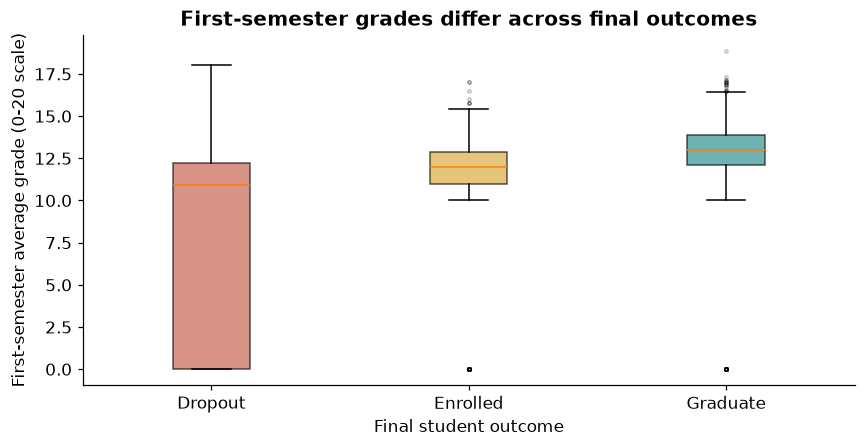

          count    mean  median    std    skew      q1      q3  zero_percent
Target                                                                      
Dropout    1421  7.2567 10.9286 6.0311 -0.3089  0.0000 12.2000       40.1126
Enrolled    794 11.1253 12.0000 3.6751 -2.3606 11.0000 12.8571        8.9421
Graduate   2209 12.6437 13.0000 2.6990 -3.4500 12.1214 13.8571        3.4857
Zero frequencies differ across outcomes. Zeros may encode no approved units rather than a conventional average over passed units.
Progression and grades are intertwined; these comparisons do not establish causation.


In [23]:
outcome_box(grade1,'First-semester grades differ across final outcomes',
            'First-semester average grade (0-20 scale)','04_semester_box')
grade_summary = df.groupby('Target')[grade1].agg(['count','mean','median','std','skew']).reindex(CLASSES)
grade_summary['q1'] = df.groupby('Target')[grade1].quantile(.25)
grade_summary['q3'] = df.groupby('Target')[grade1].quantile(.75)
grade_summary['zero_percent'] = df.assign(zero=df[grade1].eq(0)).groupby('Target').zero.mean()*100
table(grade_summary)
grade_summary.to_csv(RESULTS/'first_semester_statistics.csv')
print('Zero frequencies differ across outcomes. Zeros may encode no approved units rather than a conventional average over passed units.')
print('Progression and grades are intertwined; these comparisons do not establish causation.')

### 4.8. Compare age groups
Calculate within-band outcome percentages and show how they vary with age at enrollment.

Target             Dropout  Enrolled  Graduate
Age at enrollment                             
<=20                   542       471      1538
21-25                  295       182       351
26-35                  376        94       183
36+                    208        47       137
Target             Dropout  Enrolled  Graduate
Age at enrollment                             
<=20               21.2466   18.4633   60.2901
21-25              35.6280   21.9807   42.3913
26-35              57.5804   14.3951   28.0245
36+                53.0612   11.9898   34.9490


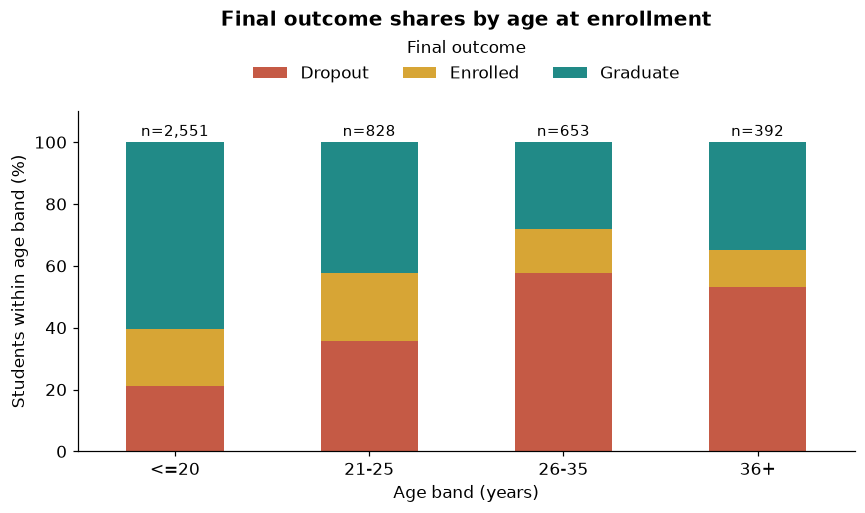

Dropout share: 21.2% for <=20, 53.1% for 36+.
Bands are descriptive, not intervention thresholds. Course mix, work and caring responsibilities may confound age associations.


In [24]:
age_band = pd.cut(df['Age at enrollment'],[0,20,25,35,np.inf],labels=['<=20','21-25','26-35','36+'])
age_counts = pd.crosstab(age_band,df.Target).reindex(columns=CLASSES)
age_percent = age_counts.div(age_counts.sum(axis=1),axis=0)*100
table(age_counts); table(age_percent)
ax = age_percent.plot.bar(stacked=True,color=COLORS,figsize=(8,4.8),rot=0)
ax.set(xlabel='Age band (years)',ylabel='Students within age band (%)',ylim=(0,110))
ax.legend(title='Final outcome',ncol=3,bbox_to_anchor=(.5,1.04),loc='lower center',frameon=False)
ax.set_title('Final outcome shares by age at enrollment',pad=56)
for i,n in enumerate(age_counts.sum(axis=1)):
    ax.text(i,102,f'n={n:,}',ha='center',fontsize=10)
finish('05_age_outcomes')
print(f"Dropout share: {age_percent.loc['<=20','Dropout']:.1f}% for <=20, {age_percent.loc['36+','Dropout']:.1f}% for 36+.")
print('Bands are descriptive, not intervention thresholds. Course mix, work and caring responsibilities may confound age associations.')

### 4.9. Test grade differences
Test H0: equal grade distributions using Kruskal-Wallis at alpha 0.05, then assess effect size, Holm-adjusted comparisons and positive-grade sensitivity.

In [25]:
groups = [df.loc[df.Target.eq(c),grade1].to_numpy() for c in CLASSES]
H,p = stats.kruskal(*groups)
epsilon2 = (H-2)/(len(df)-3)
lev = stats.levene(*groups,center='median')
test = dict(H=float(H),df=2,p=float(p),log10_p_df2=float(-H/2/np.log(10)),
            epsilon_squared=float(epsilon2),alpha=.05,
            brown_forsythe_statistic=float(lev.statistic),brown_forsythe_p=float(lev.pvalue))
print('Kruskal-Wallis:',json.dumps(test,indent=2))
print('Reject H0: grade distributions differ. This does not identify a cause or establish equal-shape median shifts.')
pairwise = []
for a,b in combinations(CLASSES,2):
    u,pv = stats.mannwhitneyu(df.loc[df.Target.eq(a),grade1],df.loc[df.Target.eq(b),grade1],
                             alternative='two-sided',method='asymptotic')
    pairwise.append(dict(comparison=a+' vs '+b,U=float(u),p_raw=float(pv)))
running = 0.
for rank,idx in enumerate(np.argsort([r['p_raw'] for r in pairwise])):
    running = max(running,min(1,(3-rank)*pairwise[idx]['p_raw']))
    pairwise[idx]['p_holm'] = running
print(pd.DataFrame(pairwise).to_string(index=False))
positive = [g[g>0] for g in groups]
hp,pp = stats.kruskal(*positive)
test.update(positive_only_H=float(hp),positive_only_p=float(pp),
            positive_only_n=sum(map(len,positive)),
            positive_only_epsilon_squared=float((hp-2)/(sum(map(len,positive))-3)))
print('Positive-grade-only sensitivity:',{k:v for k,v in test.items() if k.startswith('positive_')})
print('Statistical significance is not an intervention effect. Examine the medians, zero rates and effect-size change.')

Kruskal-Wallis: {
  "H": 1094.1864855351168,
  "df": 2,
  "p": 2.5143375393667276e-238,
  "log10_p_df2": -237.59957642050674,
  "epsilon_squared": 0.24704512226535102,
  "alpha": 0.05,
  "brown_forsythe_statistic": 549.8691347250151,
  "brown_forsythe_p": 5.474944409256759e-214
}
Reject H0: grade distributions differ. This does not identify a cause or establish equal-shape median shifts.
          comparison        U         p_raw        p_holm
 Dropout vs Enrolled 368443.5  6.914939e-43  6.914939e-43
 Dropout vs Graduate 600098.0 1.968329e-218 5.904988e-218
Enrolled vs Graduate 524677.0  1.876891e-63  3.753783e-63
Positive-grade-only sensitivity: {'positive_only_H': 474.4684102721449, 'positive_only_p': 9.343160098324437e-104, 'positive_only_n': 3706, 'positive_only_epsilon_squared': 0.12759071300895083}
Statistical significance is not an intervention effect. Examine the medians, zero rates and effect-size change.


### 4.10. Train classification models
Use a stratified 80:20 split and train-only cross-validation, excluding second-semester and timing-uncertain inputs.

In [26]:
X,y = df.drop(columns='Target'),df.Target
train_idx,test_idx = train_test_split(df.index,test_size=.2,random_state=SEED,stratify=y)
X_train,X_test = X.loc[train_idx],X.loc[test_idx]
y_train,y_test = y.loc[train_idx],y.loc[test_idx]
uncertain = ['Debtor','Tuition fees up to date','Scholarship holder','Unemployment rate','Inflation rate','GDP']
second = [c for c in X if '2nd sem' in c]
first = [c for c in X if '1st sem' in c]
main_features = [c for c in X if c not in uncertain+second]
admission_features = [c for c in main_features if c not in first]
print('Main inputs:',len(main_features),main_features)
print('Admission-only input count:',len(admission_features))
print('Timing exclusions:',uncertain+second)
split_counts = pd.crosstab(pd.Series(np.where(df.index.isin(train_idx),'Train','Test'),index=df.index),y).reindex(columns=CLASSES)
table(split_counts)
pd.DataFrame({'row_index':df.index,'partition':np.where(df.index.isin(train_idx),'train','test')}).to_csv(RESULTS/'split_manifest.csv',index=False)
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
def build_pipeline(features):
    cats = [c for c in nominal if c in features]
    bins = [c for c in binary if c in features]
    nums = [c for c in numeric if c in features]
    prep = ColumnTransformer([
        ('numeric',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),nums),
        ('categorical',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))]),cats),
        ('binary',SimpleImputer(strategy='most_frequent'),bins)])
    return Pipeline([('prepare',prep),('model',LogisticRegression(solver='lbfgs',C=1,max_iter=3000,random_state=SEED))])
searches = {}
for name,features in [('Admission only',admission_features),('End of semester one',main_features)]:
    search = GridSearchCV(build_pipeline(features),
        {'model__C':[.1,1.,10.],'model__class_weight':[None,'balanced']},
        scoring='f1_macro',cv=cv,n_jobs=1,refit=True,error_score='raise')
    search.fit(X_train[features],y_train)
    searches[name] = search
    cv_table = pd.DataFrame(search.cv_results_)[['param_model__C','param_model__class_weight','mean_test_score','std_test_score','rank_test_score']]
    print('\nTraining CV:',name)
    table(cv_table.sort_values('rank_test_score'))
    cv_table.to_csv(RESULTS/('cv_admission.csv' if name=='Admission only' else 'cv_semester_one.csv'),index=False)
    print('Chosen:',search.best_params_,'CV macro F1:',search.best_score_)
model = searches['End of semester one'].best_estimator_

Main inputs: 24 ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Gender', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)']
Admission-only input count: 18
Timing exclusions: ['Debtor', 'Tuition fees up to date', 'Scholarship holder', 'Unemployment rate', 'Inflation rate', 'GDP', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curri


Training CV: Admission only
   param_model__C param_model__class_weight  mean_test_score  std_test_score  rank_test_score
1          0.1000                  balanced           0.5161          0.0179                1
3          1.0000                  balanced           0.5156          0.0165                2
5         10.0000                  balanced           0.5134          0.0161                3
2          1.0000                      None           0.4927          0.0179                4
4         10.0000                      None           0.4923          0.0180                5
0          0.1000                      None           0.4835          0.0155                6
Chosen: {'model__C': 0.1, 'model__class_weight': 'balanced'} CV macro F1: 0.5160894725325104



Training CV: End of semester one
   param_model__C param_model__class_weight  mean_test_score  std_test_score  rank_test_score
1          0.1000                  balanced           0.6429          0.0192                1
3          1.0000                  balanced           0.6361          0.0203                2
5         10.0000                  balanced           0.6320          0.0213                3
2          1.0000                      None           0.6150          0.0089                4
4         10.0000                      None           0.6101          0.0085                5
0          0.1000                      None           0.6008          0.0077                6
Chosen: {'model__C': 0.1, 'model__class_weight': 'balanced'} CV macro F1: 0.642919623648474


### 4.11. Evaluate held-out predictions
Compare baseline and logistic models using class metrics, macro averages and the confusion matrix.

                     accuracy  macro_precision  macro_recall  macro_f1
model                                                                 
Majority class         0.4994           0.1665        0.3333    0.2221
Admission only         0.5401           0.5078        0.5102    0.5038
End of semester one    0.7028           0.6647        0.6667    0.6594
              precision  recall  f1-score  support
Dropout          0.7657  0.6444    0.6998 284.0000
Enrolled         0.4054  0.5660    0.4724 159.0000
Graduate         0.8231  0.7896    0.8060 442.0000
macro avg        0.6647  0.6667    0.6594 885.0000
weighted avg     0.7296  0.7028    0.7120 885.0000


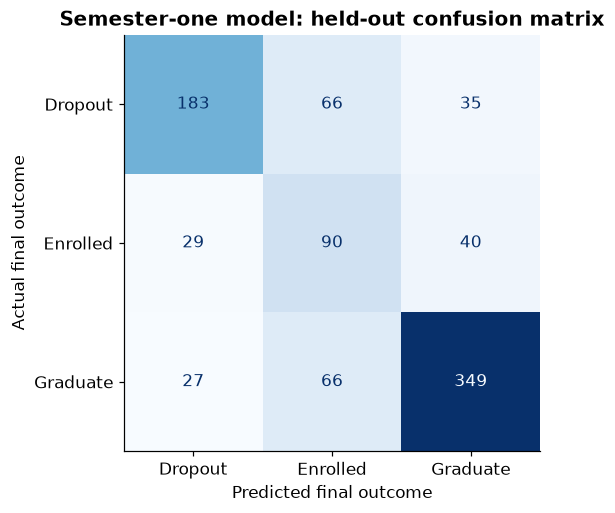

Main accuracy 70.3%; macro F1 0.659.
Lowest recall: Enrolled, 56.6%. Strong overall accuracy does not imply equal class performance.
Actual dropouts 284: identified 183, missed 101.
Dropout predictions 239: false alarms 56. Staff should review supportive outreach.


In [27]:
def score(label,actual,predicted):
    return dict(model=label,accuracy=accuracy_score(actual,predicted),
        macro_precision=precision_score(actual,predicted,average='macro',zero_division=0),
        macro_recall=recall_score(actual,predicted,average='macro',zero_division=0),
        macro_f1=f1_score(actual,predicted,average='macro',zero_division=0))
dummy = DummyClassifier(strategy='most_frequent').fit(X_train[admission_features],y_train)
comparison = [score('Majority class',y_test,dummy.predict(X_test[admission_features]))]
for name,features in [('Admission only',admission_features),('End of semester one',main_features)]:
    comparison.append(score(name,y_test,searches[name].predict(X_test[features])))
comparison = pd.DataFrame(comparison).set_index('model')
table(comparison)
comparison.to_csv(RESULTS/'model_comparison.csv')
pred = model.predict(X_test[main_features])
report = pd.DataFrame(classification_report(y_test,pred,labels=CLASSES,output_dict=True,zero_division=0)).T.drop(index='accuracy')
table(report)
report.to_csv(RESULTS/'classification_report.csv')
cm = confusion_matrix(y_test,pred,labels=CLASSES)
fig,ax = plt.subplots(figsize=(6.5,4.8))
ConfusionMatrixDisplay(cm,display_labels=CLASSES).plot(ax=ax,cmap='Blues',colorbar=False,values_format='d')
ax.set(title='Semester-one model: held-out confusion matrix',xlabel='Predicted final outcome',ylabel='Actual final outcome')
finish('06_confusion')
print(f"Main accuracy {accuracy_score(y_test,pred):.1%}; macro F1 {f1_score(y_test,pred,average='macro'):.3f}.")
worst = report.loc[CLASSES,'recall'].idxmin()
print(f"Lowest recall: {worst}, {report.loc[worst,'recall']:.1%}. Strong overall accuracy does not imply equal class performance.")
print(f'Actual dropouts {cm[0].sum()}: identified {cm[0,0]}, missed {cm[0,1:].sum()}.')
print(f'Dropout predictions {cm[:,0].sum()}: false alarms {cm[1:,0].sum()}. Staff should review supportive outreach.')
pd.DataFrame({'row_index':test_idx,'actual':y_test.to_numpy(),'predicted':pred}).to_csv(RESULTS/'test_predictions.csv',index=False)

### 4.12. Estimate score uncertainty
Bootstrap fixed test predictions 1,000 times for conditional 95% accuracy and macro-F1 intervals.

In [28]:
rng = np.random.default_rng(SEED)
actual = y_test.to_numpy()
positions = [np.flatnonzero(actual==c) for c in CLASSES]
boot = []
for _ in range(1000):
    idx = np.concatenate([rng.choice(pos,len(pos),replace=True) for pos in positions])
    boot.append([accuracy_score(actual[idx],pred[idx]),f1_score(actual[idx],pred[idx],average='macro')])
intervals = pd.DataFrame(np.quantile(boot,[.025,.975],axis=0).T,index=['accuracy','macro_f1'],columns=['lower_95','upper_95'])
table(intervals)
intervals.to_csv(RESULTS/'bootstrap_intervals.csv')

          lower_95  upper_95
accuracy    0.6757    0.7333
macro_f1    0.6296    0.6905


### 4.13. Interpret coefficients
Read Dropout-versus-Graduate coefficient differences as conditional associations, not causal effects.

In [29]:
prep,clf = model.named_steps['prepare'],model.named_steps['model']
names = prep.get_feature_names_out()
diff = clf.coef_[list(clf.classes_).index('Dropout')]-clf.coef_[list(clf.classes_).index('Graduate')]
coef_all = pd.DataFrame({'feature':names,'dropout_vs_graduate_log_odds':diff,'odds_multiplier':np.exp(diff)})
coef_all.to_csv(RESULTS/'all_coefficients.csv',index=False)
interpret_cols = [approved1,grade1,'Admission grade','Age at enrollment','Previous qualification (grade)','Gender','Displaced']
num_features = [c for c in numeric if c in main_features]
scales = dict(zip(num_features,prep.named_transformers_['numeric'].named_steps['scale'].scale_))
coef_rows = []
for c in interpret_cols:
    prefix = 'numeric__' if c in num_features else 'binary__'
    row = coef_all.loc[coef_all.feature.eq(prefix+c)].iloc[0]
    coef_rows.append(dict(feature=c,change=f'+1 SD ({scales[c]:.2f})' if c in scales else '0 to 1',
                         log_odds_difference=row.dropout_vs_graduate_log_odds,odds_multiplier=row.odds_multiplier))
coefficients = pd.DataFrame(coef_rows)
table(coefficients)
coefficients.to_csv(RESULTS/'interpreted_coefficients.csv',index=False)
print('Multipliers <1 mean lower fitted Dropout-to-Graduate odds; >1 mean higher odds, holding other encoded inputs fixed.')
print('Gender is a dataset binary code, not a complete representation of identity. Demographic coefficients do not justify exclusion.')
print('Investigate academic advising after low approvals, flexible support for older learners, and individual progress reviews for Enrolled students.')
print('Limitations: observational single-institution data; missing timestamps and checkpoint risk set; zero-grade semantics; class imbalance; linear log-odds and correlated predictors; unvalidated fairness and calibration.')

                               feature         change  log_odds_difference  odds_multiplier
0  Curricular units 1st sem (approved)   +1 SD (3.10)              -3.1992           0.0408
1     Curricular units 1st sem (grade)   +1 SD (4.87)              -0.5664           0.5676
2                      Admission grade  +1 SD (14.53)              -0.1614           0.8509
3                    Age at enrollment   +1 SD (7.60)               0.3082           1.3610
4       Previous qualification (grade)  +1 SD (13.20)              -0.0227           0.9775
5                               Gender         0 to 1               0.5487           1.7310
6                            Displaced         0 to 1               0.1225           1.1303
Multipliers <1 mean lower fitted Dropout-to-Graduate odds; >1 mean higher odds, holding other encoded inputs fixed.
Gender is a dataset binary code, not a complete representation of identity. Demographic coefficients do not justify exclusion.
Investigate academic 

### 4.14. Save and verify results
Save the statistical and model outputs and verify split separation, convergence and confusion-matrix totals.

In [30]:
summary = dict(audit=audit,versions=versions,sha256=hashlib.sha256(DATA.read_bytes()).hexdigest(),
    class_distribution=distribution.to_dict(orient='index'),test=test,pairwise=pairwise,
    grade_summary=grade_summary.to_dict(orient='index'),admission_medians=adm_medians.to_dict(),
    age_counts=age_counts.to_dict(orient='index'),age_percent=age_percent.to_dict(orient='index'),
    split_counts=split_counts.to_dict(orient='index'),main_features=main_features,
    admission_features=admission_features,excluded=uncertain+second,
    comparison=comparison.to_dict(orient='index'),classification=report.to_dict(orient='index'),
    confusion_matrix=cm.tolist(),intervals=intervals.to_dict(orient='index'),
    coefficients=coefficients.to_dict(orient='records'),
    selection={k:dict(parameters=v.best_params_,cv_macro_f1=float(v.best_score_),
                      cv_sd=float(v.cv_results_['std_test_score'][v.best_index_])) for k,v in searches.items()})
(RESULTS/'analysis_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
assert cm.sum() == len(y_test)
assert len(set(train_idx).intersection(test_idx)) == 0
assert 'Target' not in main_features and not any('2nd sem' in c for c in main_features)
assert all(max(s.best_estimator_.named_steps['model'].n_iter_)<3000 for s in searches.values())
print('Verification passed: disjoint split, expected labels, no second-semester inputs, convergence, and confusion-matrix totals.')

Verification passed: disjoint split, expected labels, no second-semester inputs, convergence, and confusion-matrix totals.
